# Football Managerial Decision Analytics — Chapter 05
## Statistical inference, uncertainty, clustering and models

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate (or fetch) the project code, import the shared package, load the workspace
import os, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/blazingarrows1525/football-managerial-decision-analytics"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists()), None)
if ROOT is None:  # opened on its own (e.g. Google Colab): fetch the project code once, next to this notebook
    ROOT = Path.cwd() / "football-managerial-decision-analytics"
    if not (ROOT / "src" / "workspace.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("FMA_PROJECT_ROOT", str(ROOT))  # data cache and outputs live inside the project folder

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.8s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## G · Statistical inference and uncertainty

**Research question.** Which relationships are in the data, how large are they, and how much could be chance?

**Method.** Rank-based statistics by default (the metrics are skewed), effect sizes and bootstrap intervals
next to every p-value, Benjamini–Hochberg control across a family of tests, and resampling at the level of the
independent unit — matches for team questions, players for player questions. Events are never treated as
independent observations.

,variable,n,pearson_r,pearson_p,spearman_rho,spearman_p,rho_ci_low,rho_ci_high,kendall_tau,kendall_p,spearman_q_BH
0,xg_against,34,-0.445,0.008,-0.428,0.012,-0.722,-0.054,-0.341,0.009,0.093
1,shots_against,34,-0.385,0.024,-0.396,0.020,-0.678,-0.062,-0.311,0.019,0.093
2,xg,34,0.480,0.004,0.374,0.029,-0.032,0.655,0.257,0.048,0.093
3,pass_completion_pct,34,0.333,0.055,0.365,0.034,0.011,0.652,0.269,0.038,0.093
4,ppda,34,0.290,0.096,0.233,0.184,-0.141,0.577,0.173,0.182,0.405
5,possession_proxy_pct,34,0.069,0.697,0.120,0.499,-0.234,0.492,0.094,0.471,0.900
6,set_piece_shots,34,-0.077,0.665,-0.069,0.699,-0.416,0.276,-0.060,0.654,0.900
7,shots,34,0.030,0.867,0.065,0.714,-0.305,0.427,0.053,0.689,0.900
8,progressive_passes,34,-0.131,0.459,-0.060,0.737,-0.420,0.338,-0.024,0.854,0.900
9,pressures,34,0.086,0.630,0.007,0.969,-0.386,0.369,-0.036,0.782,1.000


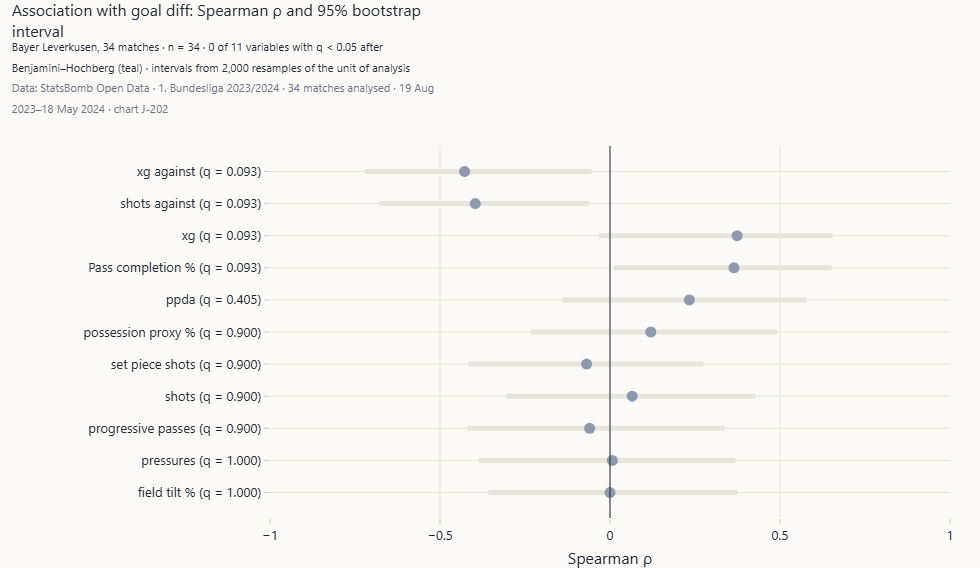

`J-202` Correlation forest plot with confidence intervals · *Method:* Spearman ρ, 2,000 match-level bootstrap resamples, Benjamini–Hochberg. · *Caveat:* One team-season: low power; association only.

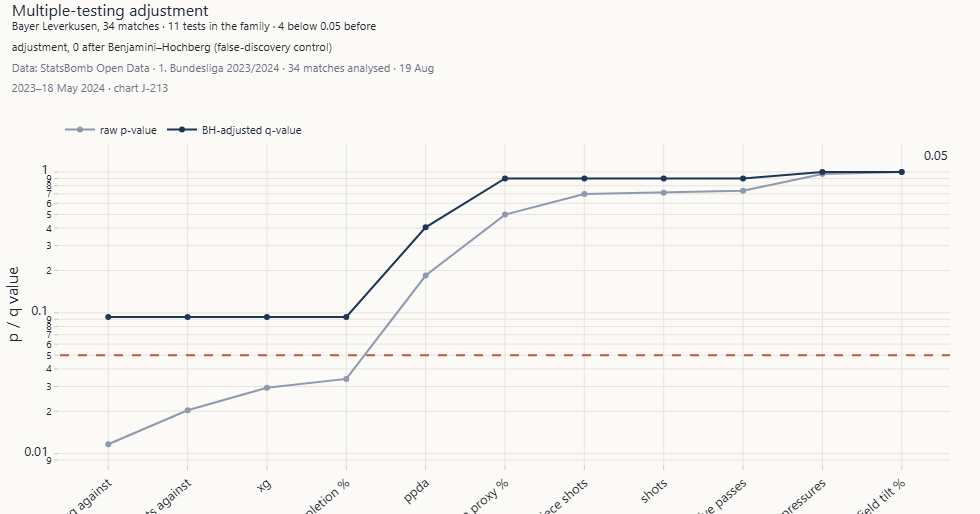

`J-213` Multiple-testing adjusted p-values · *Method:* Raw p vs Benjamini–Hochberg q.

**Interpretation.** Of 11 match variables, 0 remain associated with goal difference after false-discovery control (n = 34 matches). The strongest is xg_against (ρ = -0.43, 95% CI -0.72 to -0.05, q = 0.093); possession proxy shows ρ = 0.12 (q = 0.900).

In [2]:
from src.analytics import statistical_tests as stt
corr = ws.correlations()
display(corr.round(3))
show("J-202", ws)
show("J-213", ws)
top = corr.iloc[0]; poss = corr.set_index("variable").loc["possession_proxy_pct"]
n_sig = int((corr.spearman_q_BH < 0.05).sum())
interpret(f"Of {len(corr)} match variables, {n_sig} remain associated with goal difference after false-discovery control "
          f"(n = {int(top.n)} matches). The strongest is {top.variable} (ρ = {top.spearman_rho:.2f}, 95% CI {top.rho_ci_low:.2f} to "
          f"{top.rho_ci_high:.2f}, q = {top.spearman_q_BH:.3f}); possession proxy shows ρ = {poss.spearman_rho:.2f} (q = {poss.spearman_q_BH:.3f}).")

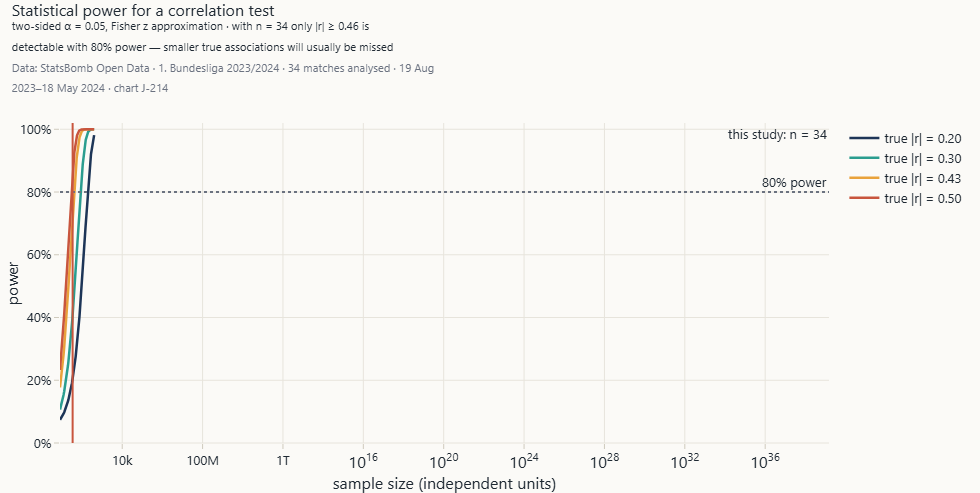

`J-214` Power / sensitivity curve · *Method:* Power of a two-sided correlation test by n. · *Caveat:* Fisher z approximation.

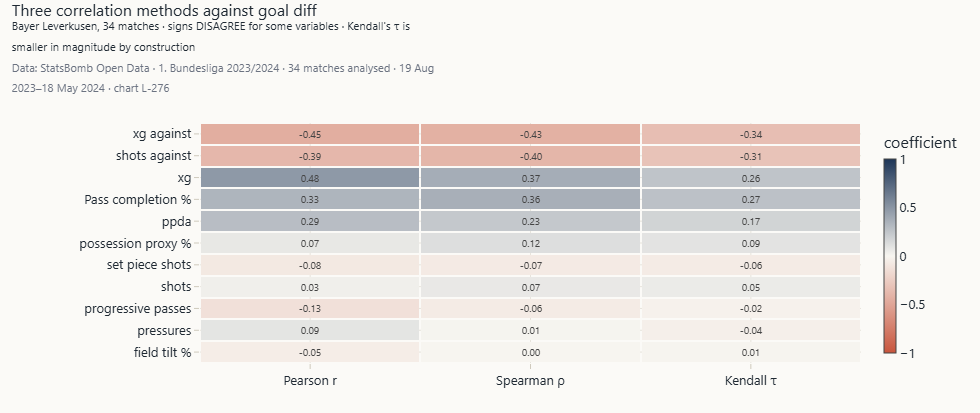

`L-276` Three correlation methods compared · *Method:* Three coefficients per variable.

**Interpretation.** With n = 34 a two-sided test at α = 0.05 has 80% power only for |r| ≥ 0.46. Weaker real associations will usually be missed, so a non-significant result here is not evidence of no relationship. H1 (chance quality matters more than possession) is supported in direction and undecided in significance at this sample size.

**Limitation.** One team-season: opponents and venues are not randomised, and nothing here is a causal estimate.

In [3]:
show("J-214", ws)
show("L-276", ws)
mdr = float(stt.min_detectable_correlation(len(tm)))
interpret(f"With n = {len(tm)} a two-sided test at α = 0.05 has 80% power only for |r| ≥ {mdr:.2f}. Weaker real "
          f"associations will usually be missed, so a non-significant result here is not evidence of no relationship. "
          f"H1 (chance quality matters more than possession) is supported in direction and "
          + ("in significance." if n_sig else "undecided in significance at this sample size."))
limitation("One team-season: opponents and venues are not randomised, and nothing here is a causal estimate.")

,comparison,n_a,n_b,mean_a,mean_b,mean_diff,diff_ci_low,diff_ci_high,p_value,effect_size,magnitude
0,home vs away,17,17,1.599,1.041,0.558,-0.178,1.228,0.098,0.336,medium
1,first half of season vs second half,17,17,1.254,1.387,-0.133,-0.915,0.632,0.731,-0.073,negligible
2,Bayer Leverkusen shot xG vs opponent shot xG,623,293,0.117,0.095,0.022,0.003,0.040,0.079,0.072,negligible


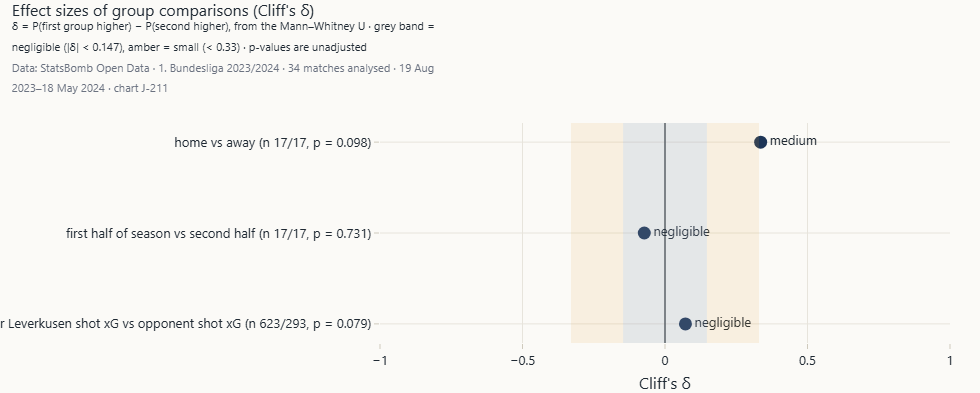

`J-211` Effect-size plot · *Method:* Cliff's δ with magnitude bands. · *Caveat:* p-values shown are unadjusted.

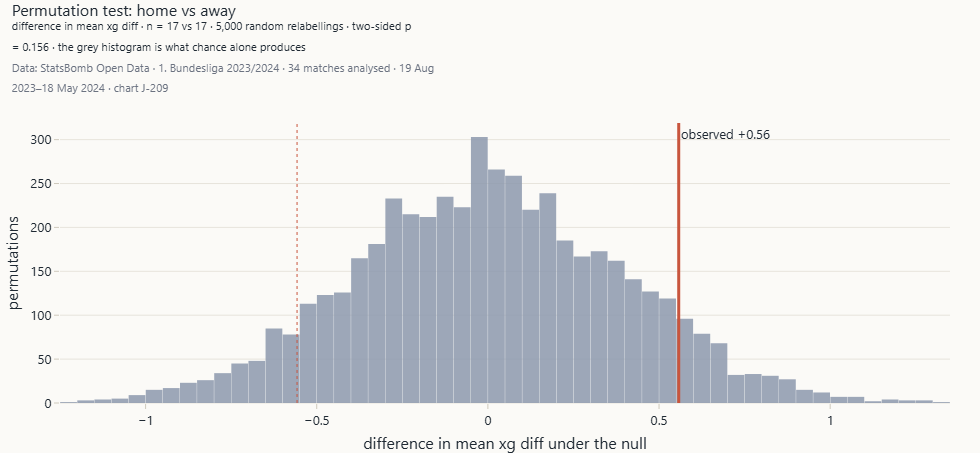

`J-209` Permutation test null distribution · *Method:* 5,000 label permutations.

**Interpretation.** Home minus away xG difference is +0.56 (95% CI -0.18 to +1.23), Cliff's δ = 0.34 (medium), p = 0.098 — suggestive but not established; the interval includes zero.

**Managerial implication.** Not strong enough to justify a different game model by venue on this evidence.

In [4]:
tests = ws.group_tests()
display(pd.DataFrame(tests)[["comparison", "n_a", "n_b", "mean_a", "mean_b", "mean_diff", "diff_ci_low", "diff_ci_high",
                             "p_value", "effect_size", "magnitude"]].round(3))
show("J-211", ws)
show("J-209", ws, team_metric="xg_diff")
v = tests[0]
interpret(f"Home minus away xG difference is {v['mean_diff']:+.2f} (95% CI {v['diff_ci_low']:+.2f} to {v['diff_ci_high']:+.2f}), "
          f"Cliff's δ = {v['effect_size']:.2f} ({v['magnitude']}), p = {v['p_value']:.3f} — "
          + ("statistically significant." if v['p_value'] < 0.05 else "suggestive but not established; the interval includes zero."))
implication("Not strong enough to justify a different game model by venue on this evidence.")

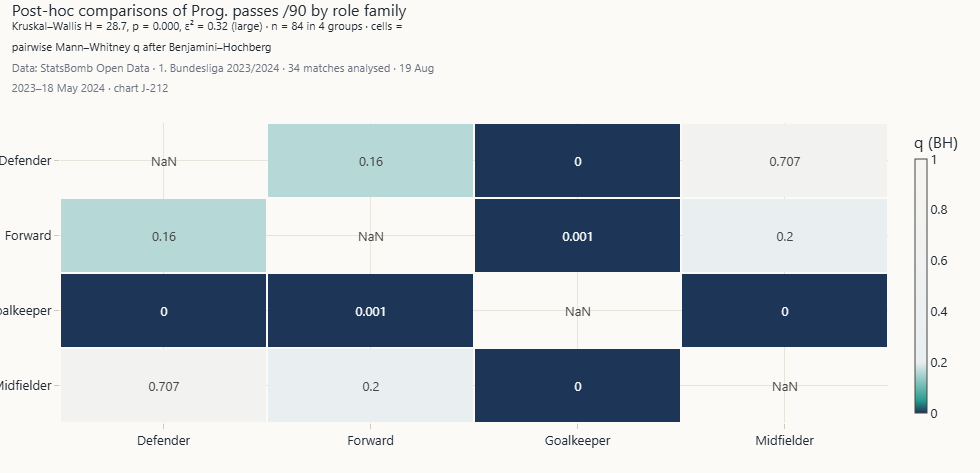

`J-212` Kruskal–Wallis post-hoc comparisons · *Method:* Pairwise Mann–Whitney with BH adjustment.

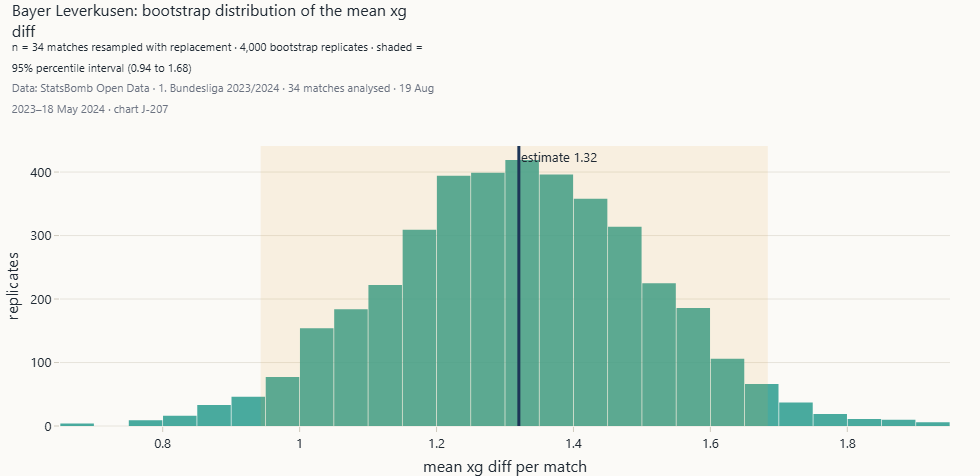

`J-207` Bootstrap distribution · *Method:* 4,000 resamples of matches.

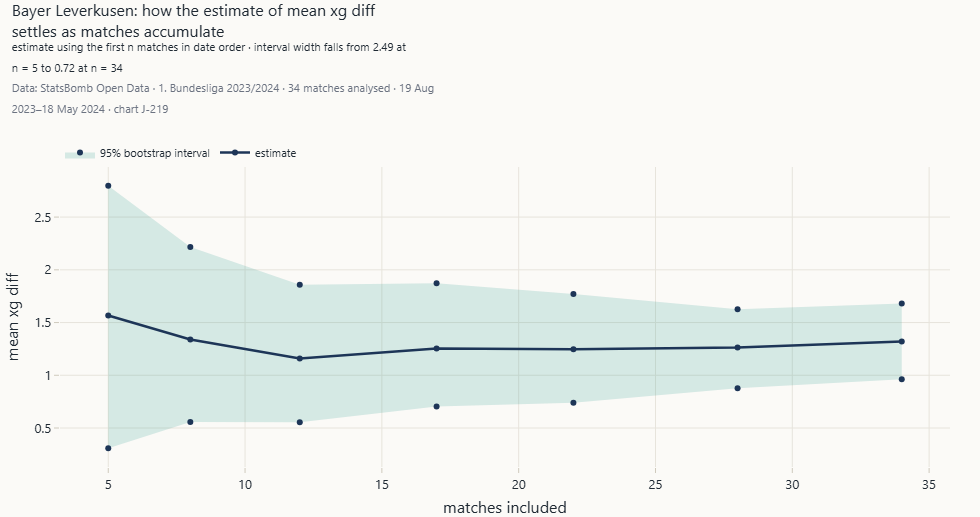

`J-219` Bootstrap stability plot · *Method:* Estimate and interval using the first n matches.

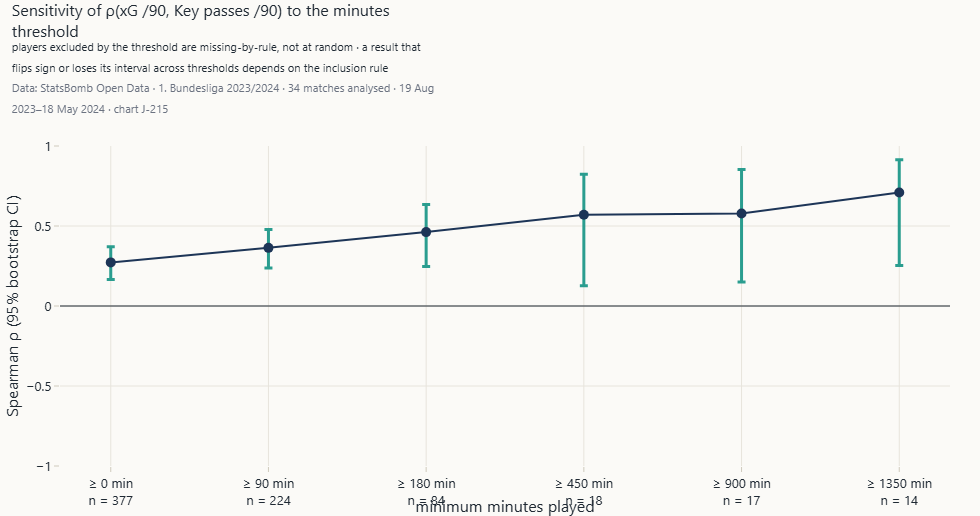

`J-215` Missing-data sensitivity · *Method:* Correlation under six inclusion rules.

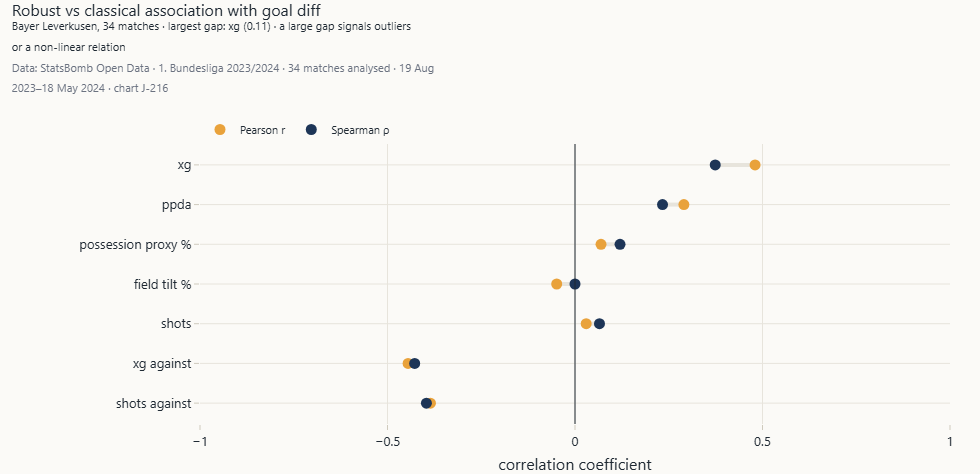

`J-216` Robust versus non-robust estimates · *Method:* Pearson vs Spearman.

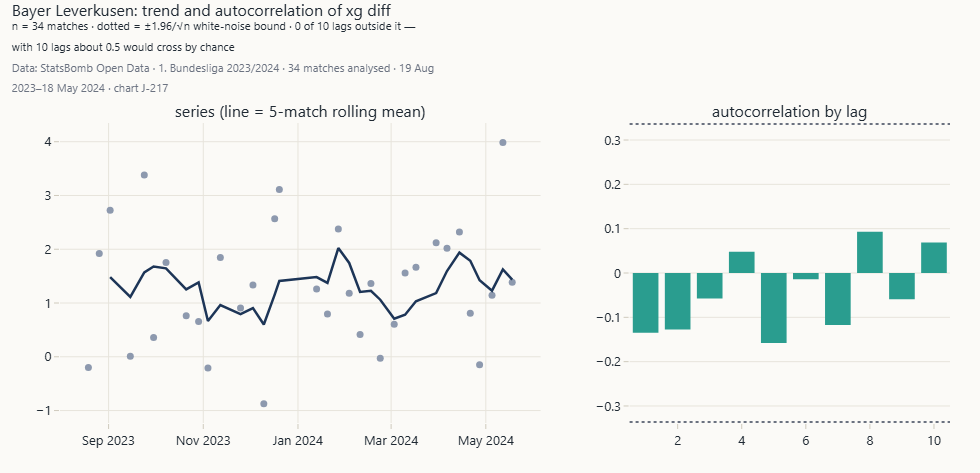

`J-217` Time trend and autocorrelation · *Method:* Series, rolling mean and autocorrelation by lag.

In [5]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("J-212", ws, metric="progressive_passes_p90", group="role_family")
    show("J-207", ws, team_metric="xg_diff")
    show("J-219", ws, team_metric="xg_diff")
    show("J-215", ws, metric="xg_p90", metric_y="key_passes_p90")
    show("J-216", ws)
    show("J-217", ws, team_metric="xg_diff")

## H · Unsupervised structure: PCA and clustering

**Question.** Do player profiles form distinct types, or a continuum?

**Method.** Fourteen per-90 metrics, standardised, for outfield players above the minutes threshold. Four
algorithms (K-Means, Ward, Gaussian mixture, DBSCAN) and four selection criteria, plus a bootstrap stability
check — so the conclusion does not rest on one method.

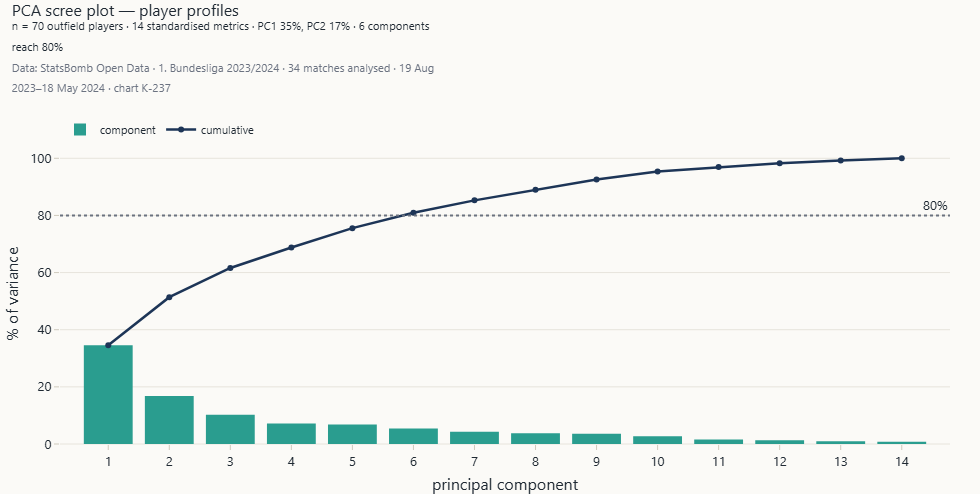

`K-237` PCA scree plot · *Method:* Explained variance with cumulative curve.

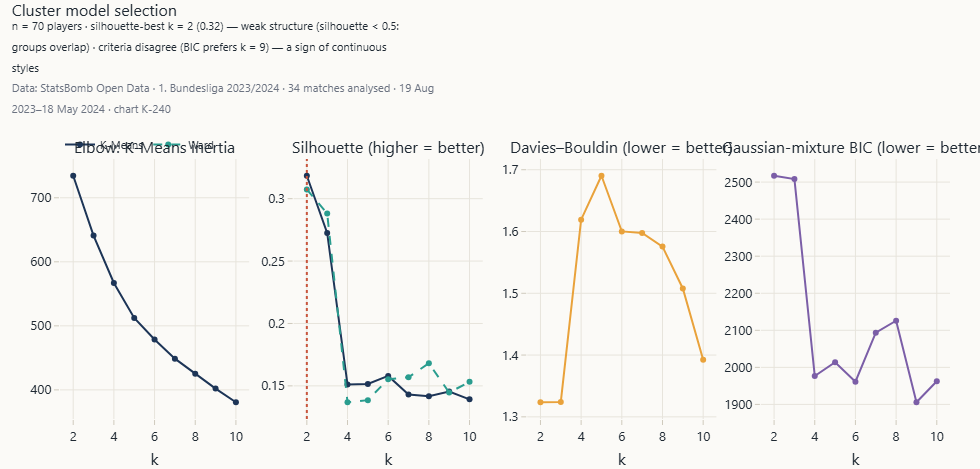

`K-240` Cluster model selection · *Method:* Elbow, silhouette, Davies–Bouldin, GMM BIC.

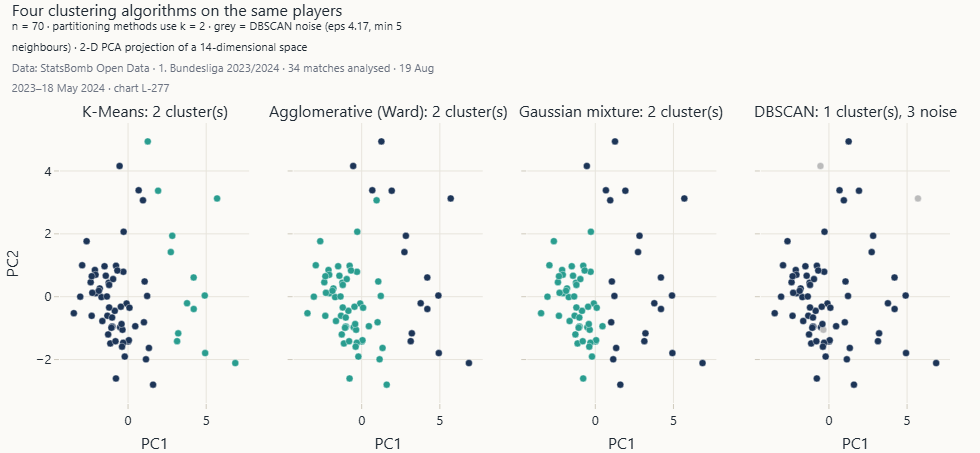

`L-277` Four clustering algorithms projected · *Method:* K-Means, Ward, GMM and DBSCAN labels in PCA space.

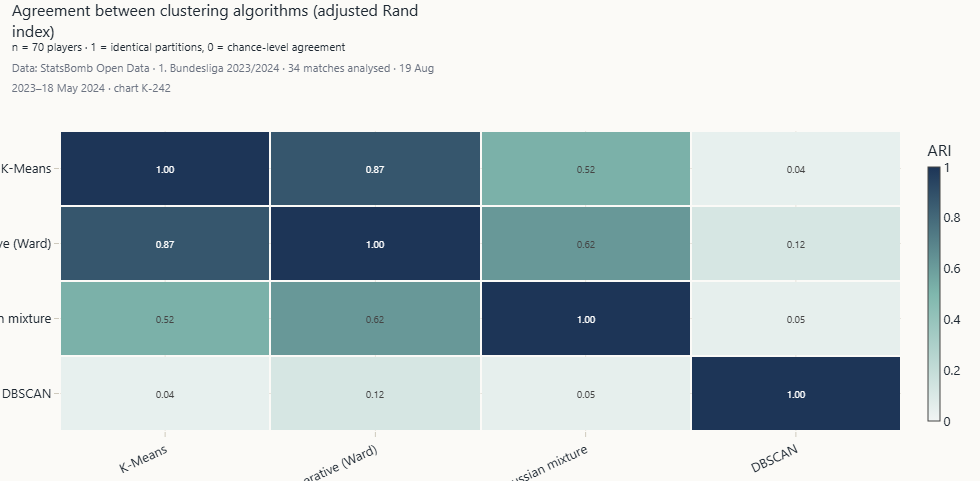

`K-242` Cluster stability / ARI comparison · *Method:* Adjusted Rand index between four algorithms.

**Interpretation.** PC1 and PC2 explain 35% and 17% of the variance across 70 players; 6 components are needed for 80%. Silhouette is best at k = 2 (0.32) while the mixture-model BIC prefers k = 9; DBSCAN finds 1 dense group(s) and 3 outlying players. Bootstrap stability of the K-Means partition: mean ARI 0.75.

**Managerial implication.** Use role-specific metric profiles for squad planning; cluster labels are a vocabulary, not fixed player types.

**Limitation.** Opponent players are observed only in their two matches against the focus team.

In [6]:
pca = ws.pca(); cl = ws.clusters()
show("K-237", ws)
show("K-240", ws)
show("L-277", ws)
show("K-242", ws)
stab = ws.cluster_stability()
interpret(f"PC1 and PC2 explain {pca['explained'][0]:.0%} and {pca['explained'][1]:.0%} of the variance across {pca['n_players']} "
          f"players; {pca['components_for_80pct']} components are needed for 80%. Silhouette is best at k = {cl['k_best']} "
          f"({cl['silhouette_best']:.2f}) while the mixture-model BIC prefers k = {cl['k_bic']}; DBSCAN finds "
          f"{cl['dbscan_clusters']} dense group(s) and {cl['dbscan_noise']} outlying players. Bootstrap stability of the "
          f"K-Means partition: mean ARI {stab.ari.mean():.2f}.")
implication("Use role-specific metric profiles for squad planning; cluster labels are a vocabulary, not fixed "
            "player types.")
limitation("Opponent players are observed only in their two matches against the focus team.")

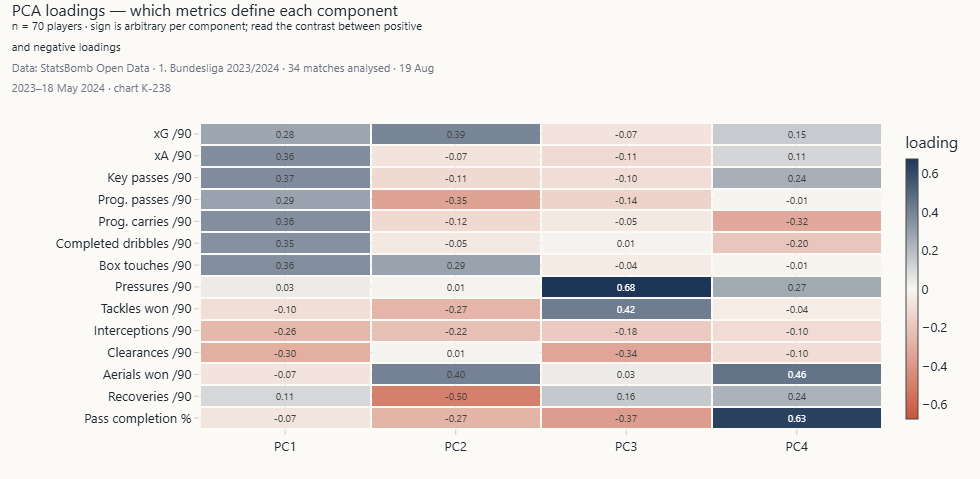

`K-238` PCA loading plot · *Method:* Loadings of the first four components.

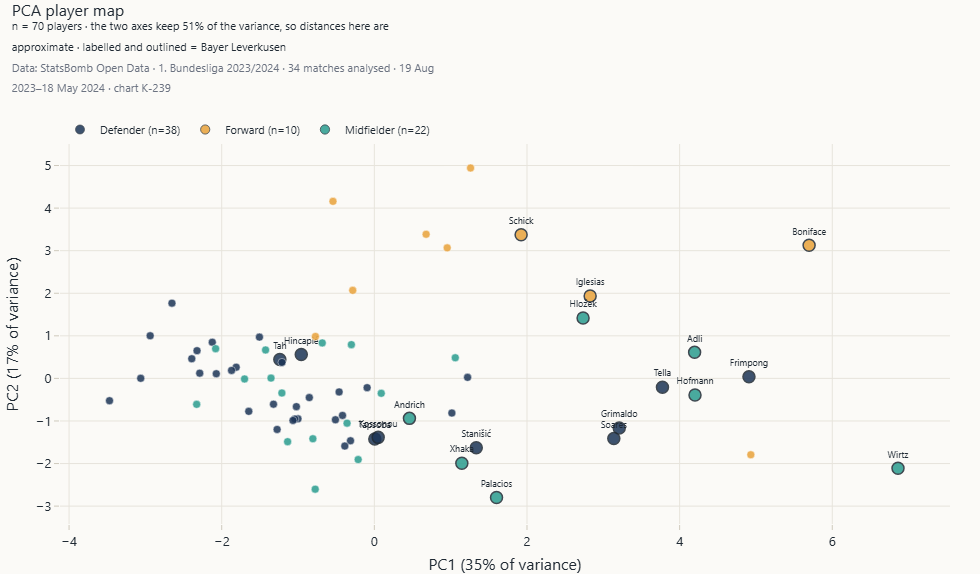

`K-239` PCA player map · *Method:* PC1 × PC2 by role family.

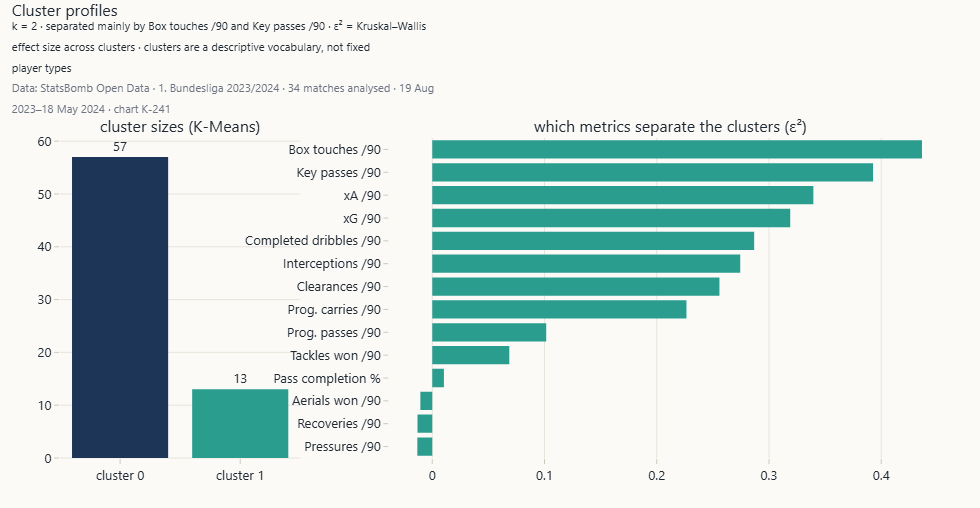

`K-241` Cluster projection and profile · *Method:* Sizes and ε² per metric.

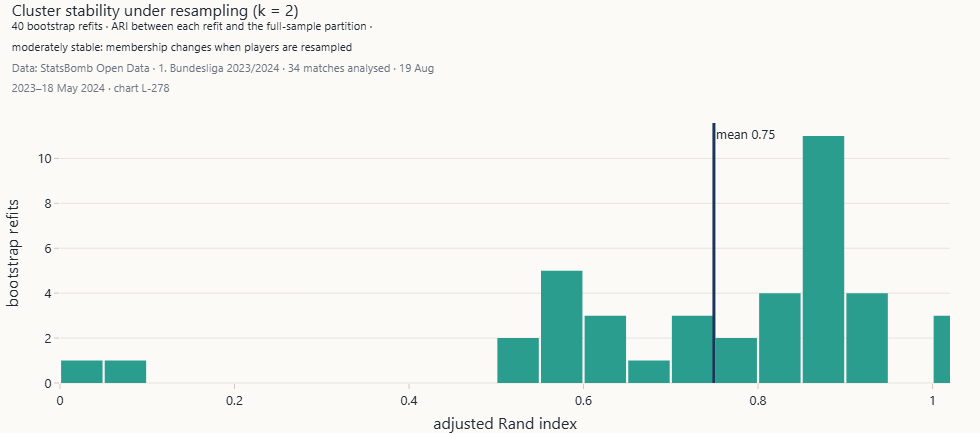

`L-278` Cluster stability under resampling · *Method:* ARI of 40 bootstrap refits against the full-sample partition.

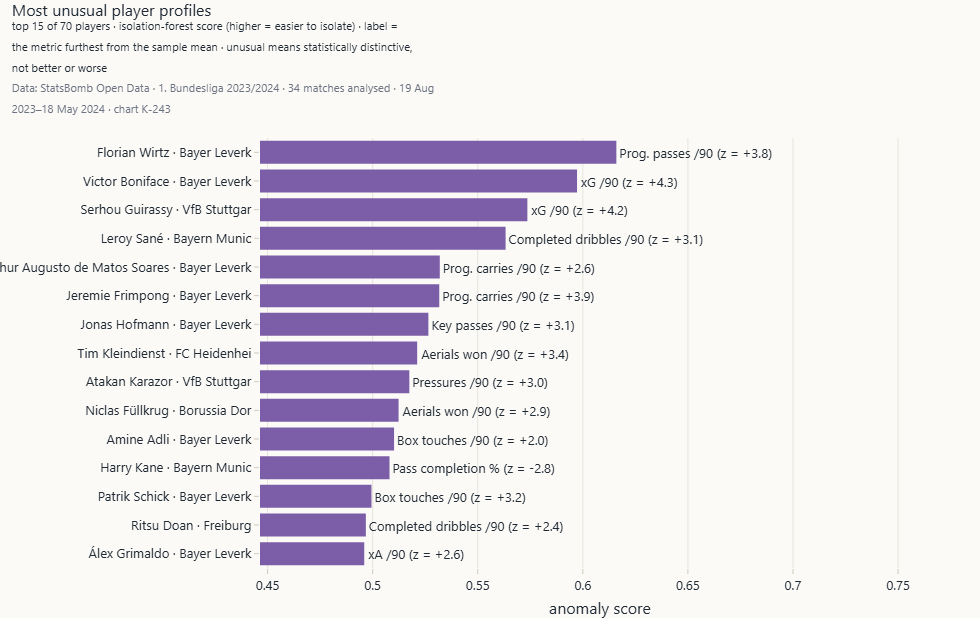

`K-243` Outlier / anomaly score chart · *Method:* Isolation-forest score. · *Caveat:* Unusual is not better or worse.

In [7]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("K-238", ws)
    show("K-239", ws)
    show("K-241", ws)
    show("L-278", ws)
    show("K-243", ws)

## Supervised modelling — only where the data support it

**Question.** Can the starting decision be predicted from information available before kick-off, and does a
model beat a simple rule?

**Target.** One row per match-day squad member of the focus team; y = 1 if he started. **Baseline:** he started
the previous match. **Split:** by match in date order (expanding-window cross-validation and a final
chronological hold-out) so no future information reaches a prediction.

**Not modelled:** match results (34 matches, no losses), goals, injuries, fitness, market value — the data do
not support them.

,rows,matches,min_rows,min_matches,class_balance_starter_pct
0,660,33,300,15,55.000


,target not modelled,why
0,Match result (win / draw / loss),34 matches of one team with no losses; the cla...
1,Goals or xG per match (regression),34 observations for a model with several predi...
2,"Injury risk, fitness or fatigue","No injury, medical, GPS or physical-load data ..."
3,Player market value,No valuation or contract data exist in the sou...


,feature,computed from,availability
0,started_prev_match,team's previous match lineup,known before kick-off
1,consecutive_starts_before,previous matches,known before kick-off
2,start_share_before,starts / team matches before this match,known before kick-off
3,minutes_share_before,minutes / (team matches x 95) before this match,known before kick-off
4,minutes_prev_7d / 14d,minutes in earlier matches within 7/14 days,known before kick-off
5,rest_days_filled,days since last appearance (60 if none),known before kick-off
6,is_gk,role from squad match position (event-derived),position played in this match — mild contempor...
7,"EXCLUDED: minutes_played, events, goals in the...",same-match outcomes,would leak — not used


accuracy       precision       recall          f1       roc_auc       pr_auc       brier      
                                     mean   std      mean   std   mean   std  mean   std    mean   std   mean   std  mean   std
model                                                                                                                          
Baseline: started previous match    0.760 0.094     0.796 0.083  0.756 0.097 0.775 0.090     NaN   NaN    NaN   NaN   NaN   NaN
Gradient boosting                   0.760 0.110     0.782 0.100  0.782 0.100 0.782 0.100   0.816 0.099  0.835 0.085 0.194 0.065
Logistic regression                 0.792 0.088     0.811 0.080  0.811 0.080 0.811 0.080   0.838 0.079  0.853 0.071 0.162 0.058
Random forest                       0.768 0.117     0.789 0.106  0.789 0.106 0.789 0.106   0.829 0.102  0.844 0.091 0.164 0.060

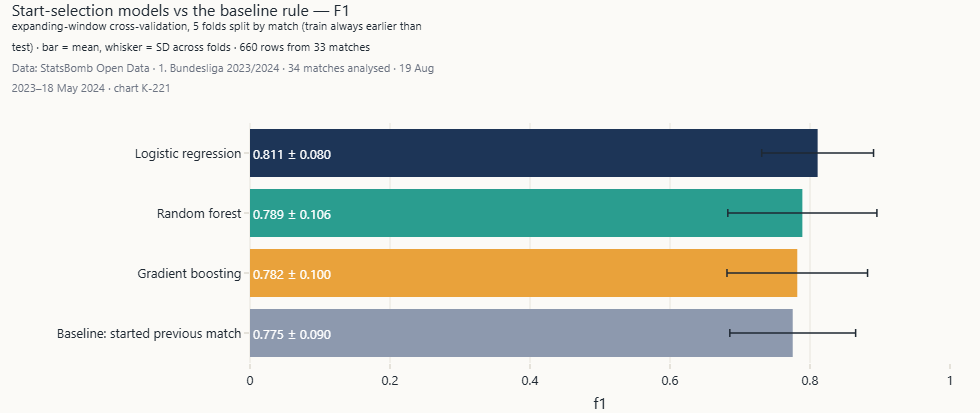

`K-221` Baseline model comparison · *Method:* Expanding-window CV split by match; baseline = started previous match. · *Caveat:* Target = start selection of the focus team; nothing generalises beyond this team-season.

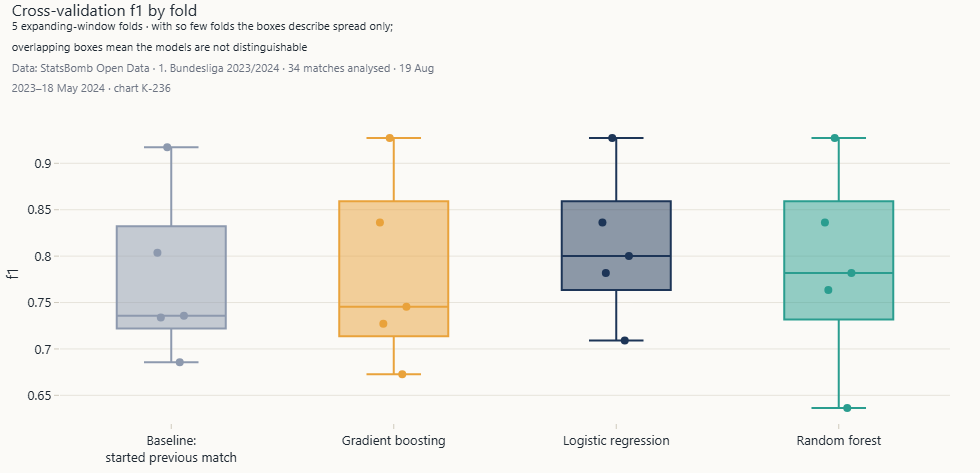

`K-236` Cross-validation score distribution · *Method:* One point per time-ordered fold.

**Interpretation.** Time-ordered cross-validation on 660 rows from 33 matches: F1 Baseline: started previous match 0.775, Gradient boosting 0.782, Logistic regression 0.811, Random forest 0.789. ROC-AUC ranges from 0.816 to 0.838. The best model improves on the baseline rule by 0.036 F1.

In [8]:
from src.analytics import models
with timed("model comparison"):
    res = ws.models()
display(pd.DataFrame([res["gate"]]))
display(pd.DataFrame(models.UNSUPPORTED_TARGETS, columns=["target not modelled", "why"]))
if res["fitted"]:
    display(res["leakage_audit"])
    cs = res["cv_summary"]; display(cs.round(3))
    show("K-221", ws); show("K-236", ws)
    f1 = cs[("f1", "mean")]; auc = cs[("roc_auc", "mean")].dropna()
    interpret(f"Time-ordered cross-validation on {res['gate']['rows']} rows from {res['gate']['matches']} matches: F1 "
              + ", ".join(f"{m} {v:.3f}" for m, v in f1.items())
              + f". ROC-AUC ranges from {auc.min():.3f} to {auc.max():.3f}. The best model improves on the baseline rule by "
              f"{f1.drop(models.BASELINE_NAME).max() - f1[models.BASELINE_NAME]:.3f} F1.")
else:
    interpret(f"No model is fitted: {res['reason']}")

Hold-out: train 23 matches to 03 Mar 2024, test 10 matches from 10 Mar 2024


,model,precision,recall,f1,brier,roc_auc,pr_auc
0,Baseline: started previous match,0.743,0.682,0.711,0.305,NaN,NaN
1,Logistic regression,0.745,0.745,0.745,0.197,0.775,0.797
2,Random forest,0.718,0.718,0.718,0.201,0.753,0.776
3,Gradient boosting,0.700,0.700,0.700,0.237,0.737,0.777


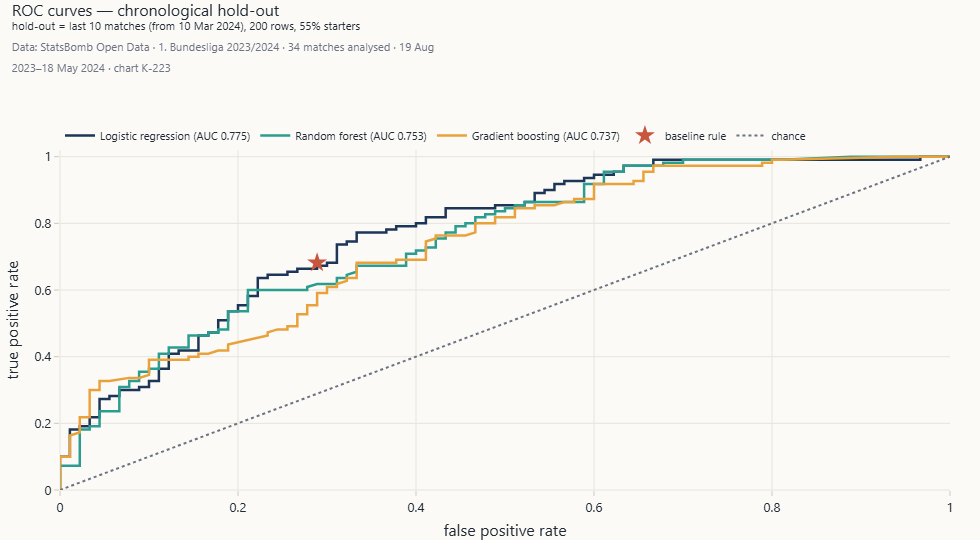

`K-223` ROC curve · *Method:* Chronological hold-out; baseline as a point.

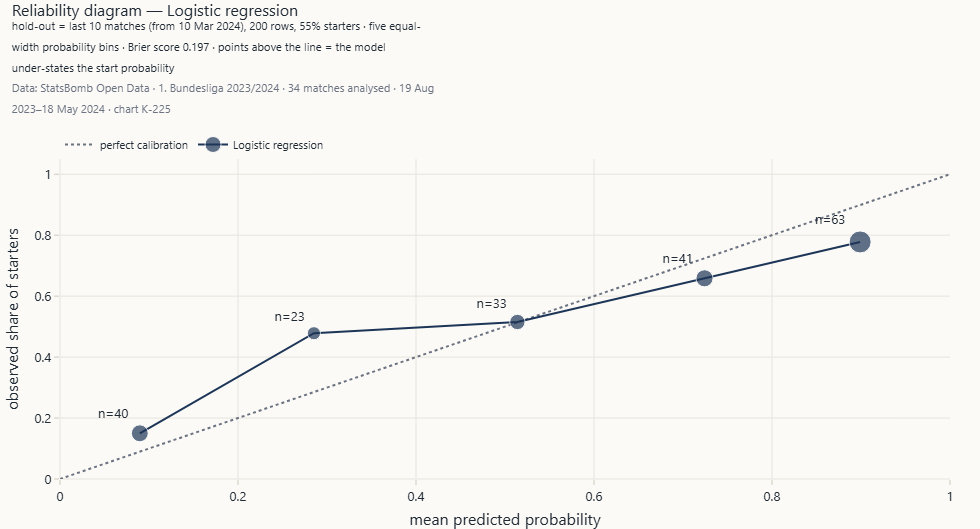

`K-225` Calibration curve · *Method:* Five probability bins with n.

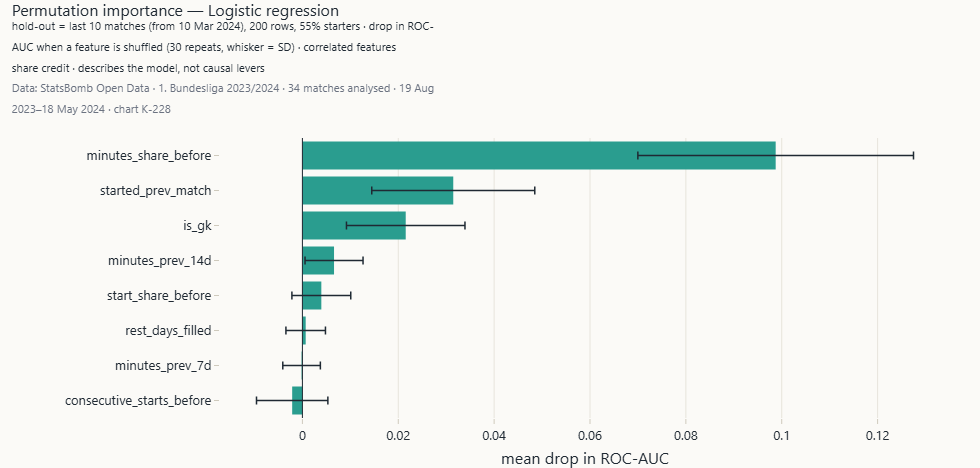

`K-228` Permutation feature importance · *Method:* Drop in hold-out ROC-AUC, 30 repeats. · *Caveat:* Describes the model, not causal levers.

**Interpretation.** On the chronological hold-out Logistic regression ranks starters best (ROC-AUC 0.775, Brier 0.197). Shuffling minutes_share_before costs 0.099 AUC and started_prev_match 0.031: selection follows past selection.

**Managerial implication.** A rule plus season minutes share explains most selections. Analytics adds value in the rotation margin — where the missing availability data matter most.

**Limitation.** Describes this team-season only; importance is conditional on correlated features and is not a causal lever.

In [9]:
if res["fitted"]:
    s = res["split"]; hold = res["holdout"].set_index("model")
    print(f"Hold-out: train {s['train_matches']} matches to {s['train_until']:%d %b %Y}, test {s['test_matches']} matches from {s['test_from']:%d %b %Y}")
    display(res["holdout"].round(3))
    show("K-223", ws); show("K-225", ws); show("K-228", ws)
    perm = ws.permutation()
    interpret(f"On the chronological hold-out {res['best']} ranks starters best (ROC-AUC {hold.loc[res['best'], 'roc_auc']:.3f}, "
              f"Brier {hold.loc[res['best'], 'brier']:.3f}). Shuffling {perm.feature.iloc[-1]} costs {perm.importance_mean.iloc[-1]:.3f} AUC "
              f"and {perm.feature.iloc[-2]} {perm.importance_mean.iloc[-2]:.3f}: selection follows past selection.")
    implication("A rule plus season minutes share explains most selections. Analytics adds value in the rotation "
                "margin — where the missing availability data matter most.")
    limitation("Describes this team-season only; importance is conditional on correlated features and is not a "
               "causal lever.")

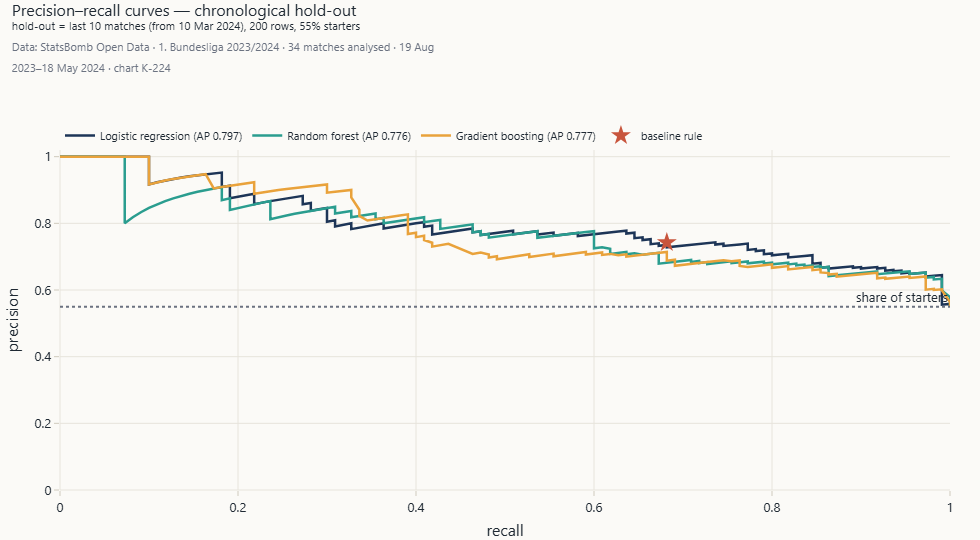

`K-224` Precision–recall curve · *Method:* With the positive-class rate as reference.

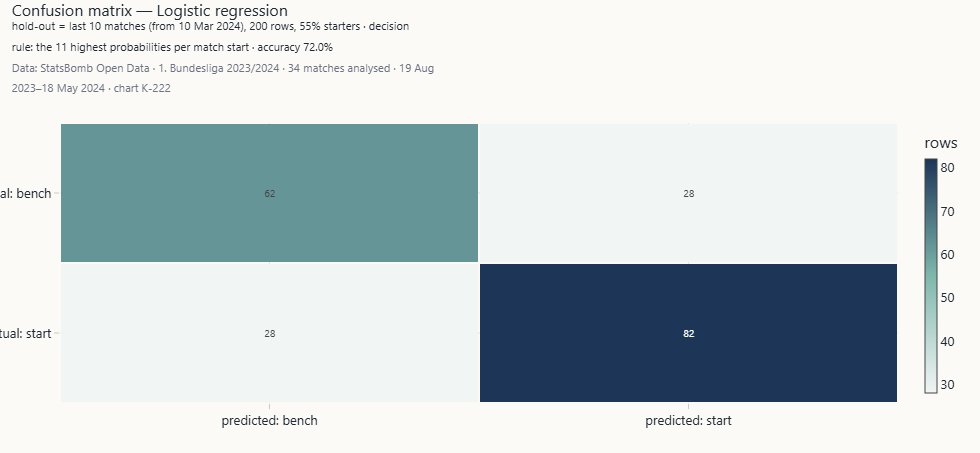

`K-222` Confusion matrix · *Method:* Top-11 decision rule on the hold-out.

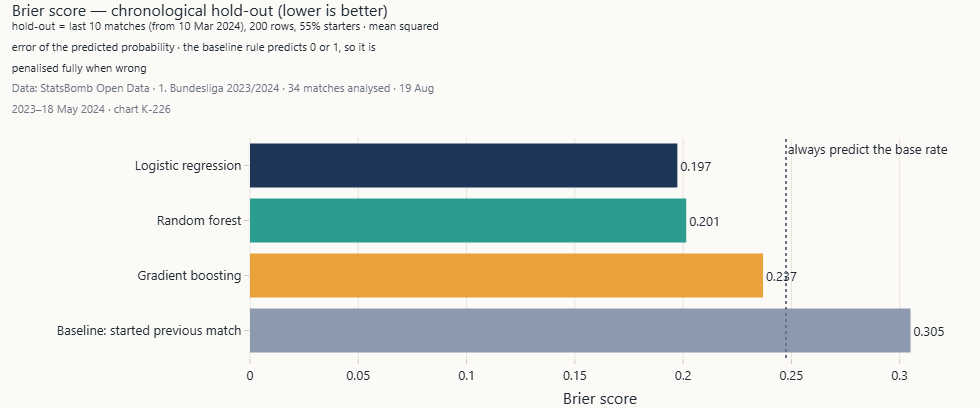

`K-226` Brier score comparison · *Method:* Lower is better; base-rate reference shown.

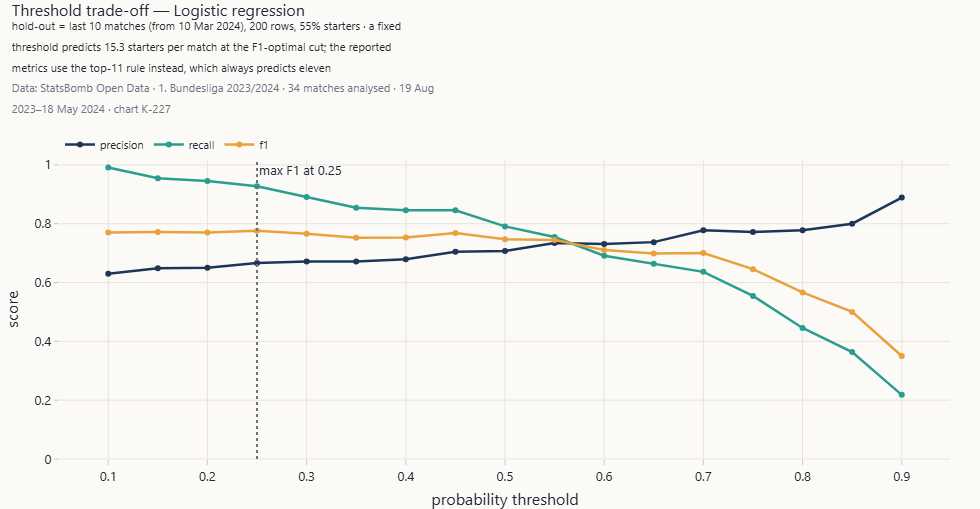

`K-227` Threshold trade-off chart · *Method:* Precision, recall and F1 by threshold.

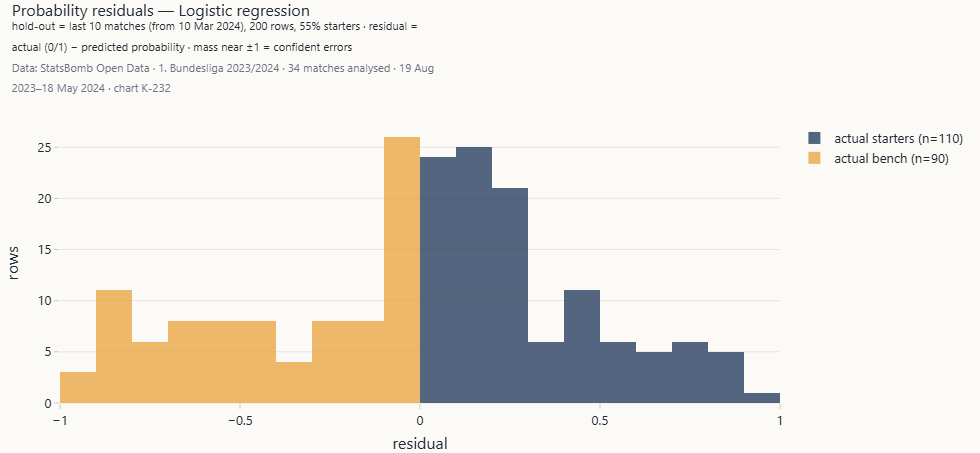

`K-232` Residual distribution · *Method:* Actual − predicted probability, by outcome.

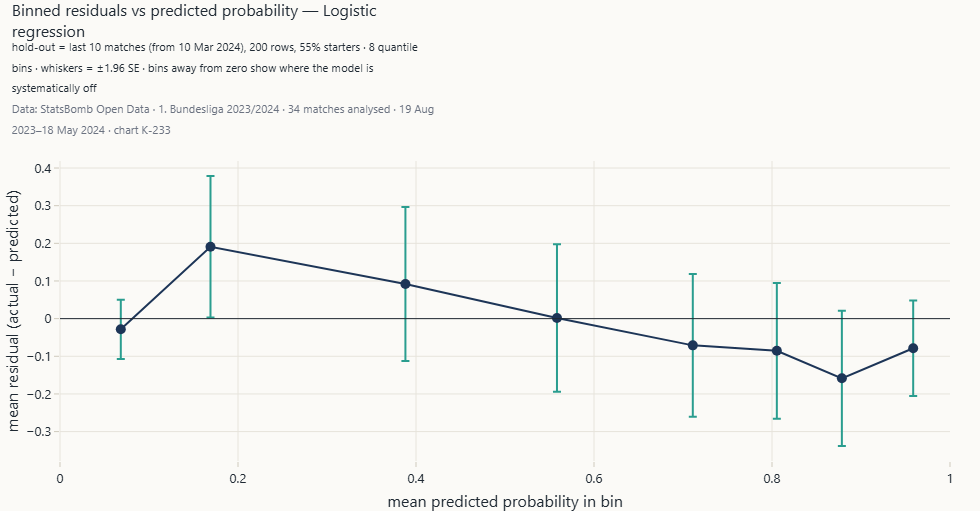

`K-233` Residual versus fitted plot · *Method:* Binned residuals with ±1.96 SE.

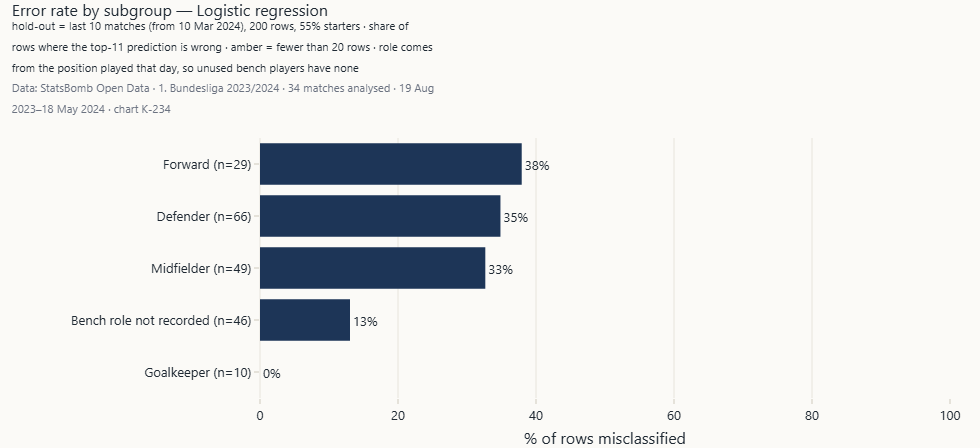

`K-234` Error by subgroup · *Method:* Error rate by role family.

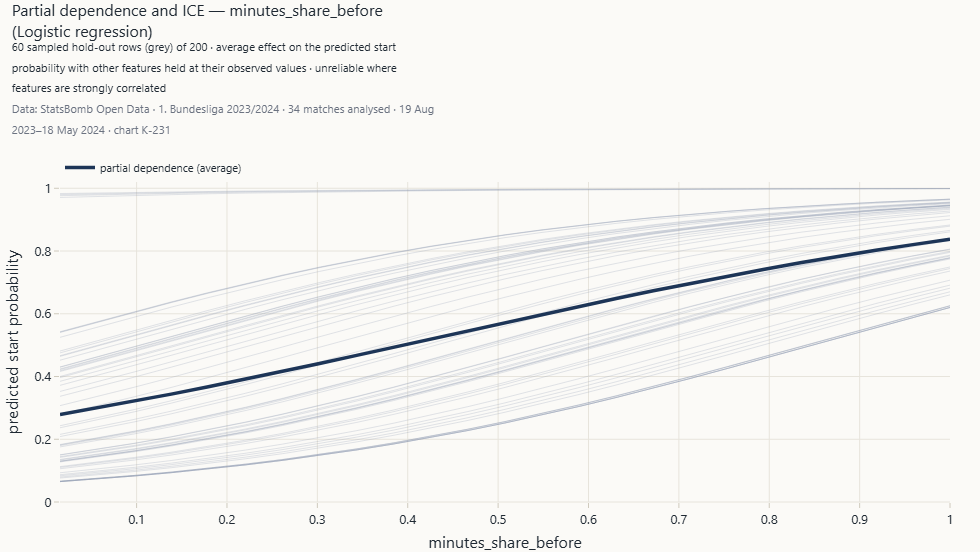

`K-231` Partial dependence / ICE · *Method:* PDP over ICE curves.

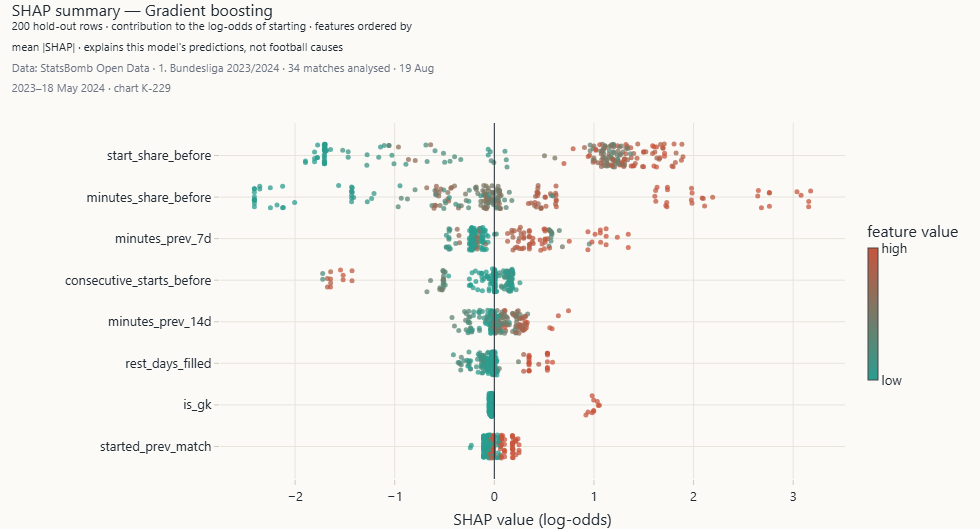

`K-229` SHAP summary · *Method:* TreeExplainer on gradient boosting, hold-out rows.

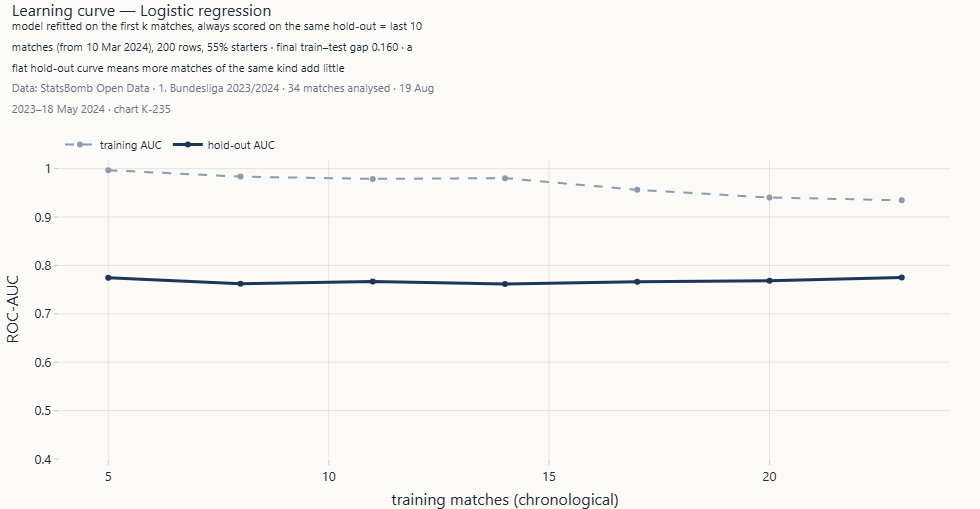

`K-235` Learning curve · *Method:* Training and hold-out AUC by training matches.

In [10]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    if res["fitted"]:
        for cid in ("K-224", "K-222", "K-226", "K-227", "K-232", "K-233", "K-234", "K-231", "K-229", "K-235"):
            show(cid, ws)